## Problem 19 (14/100 points): Explainability

This problem focuses on explainability using Captum.

Following examples we have discussed in class, do the following:
* Load the standard MNIST training and test sets.
* Build and train a PyTorch classifier that achieves greater than 90% accuracy on the test set. If you tune the model, use a validation split from the training set; reserve the test set for final evaluation. Print the final test accuracy.
* Choose 10 distinct samples at random from the test set, using a sampling seed of 42. Put your model in evaluation mode and use Captum's integrated gradients to attribute each image's predicted-class score to its input pixels. Use the predicted class as the attribution target, even if the prediction is incorrect.
* Use an all-black image as the attribution baseline. Apply the same preprocessing to the baseline as to the input images; if you normalize inputs, the baseline must represent black after that normalization. State your preprocessing and baseline choice.
* Display each of the 10 images alongside its attribution heatmap, with the true and predicted labels. Explain the heatmap's color scale and whether it shows signed contributions or their magnitudes. Briefly interpret each map, describing which regions contribute most to the predicted-class score relative to the baseline.
* Export your trained model in evaluation mode to an ONNX file using `torch.onnx.export`.

Notes:
* Run `uv sync` from the repository root to install the required dependencies, including Captum, ONNX, and ONNX Script. Use the project's `.venv` notebook kernel.
* Submit the notebook with its accuracy output, attribution plots, explanations, and export code. You do not need to commit the model file or downloaded MNIST data.
* MNIST is a solved problem. If you choose the right model and tune it well, it should fit quickly.
* If you get stuck, remember best practices for model tuning.

This is an open-ended coding problem testing PyTorch for model construction and training, Captum for attribution, and ONNX for model export. You may use other tools in addition to these required tools.

This problem will be graded manually.

54000 6000 10000
Final test accuracy: 0.9648
test indices: [7542, 8214, 3698, 2841, 8086, 2550, 2282, 7599, 1462, 2026]
baseline value after normalization: tensor([-0.4242])
attribution sums: tensor([12.4086, 25.6784, 17.7034, 25.0962, 16.3321, 22.0066, 15.8585, 16.3033,
        22.4112, 24.9371])
score differences: tensor([12.4076, 25.6732, 17.6975, 25.0875, 16.3454, 22.0050, 15.8632, 16.2893,
        22.4114, 24.9316])
convergence delta: tensor([ 0.0010,  0.0051,  0.0059,  0.0087, -0.0133,  0.0016, -0.0047,  0.0140,
        -0.0002,  0.0055])


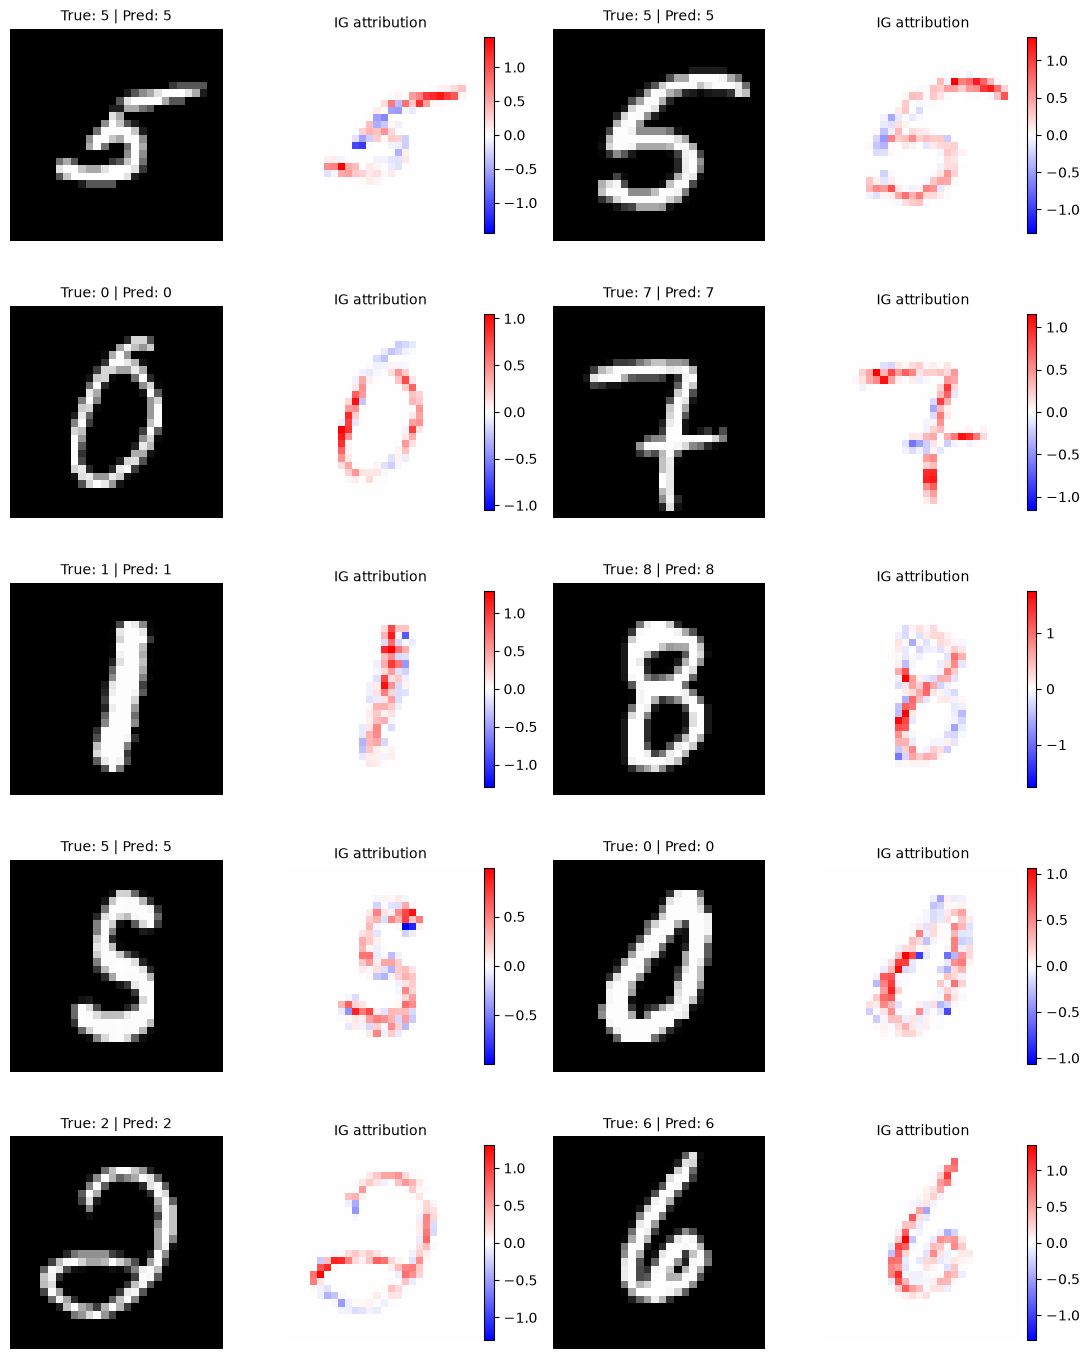

[torch.onnx] Obtain model graph for `MNISTClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MNISTClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX export OK


In [6]:


# Your code here


import numpy as np
import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.optim.lr_scheduler import StepLR
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients

torch.manual_seed(1) 
device = torch.device("cpu")      


MEAN, STD = 0.1307, 0.3081        # standard MNIST statistics
normalize = transforms.Normalize((MEAN,), (STD,))
tf = transforms.Compose([transforms.ToTensor(), normalize])

full_train = datasets.MNIST("../data", train=True,  download=True, transform=tf)
test_set   = datasets.MNIST("../data", train=False, download=True, transform=tf)

train_set, val_set = torch.utils.data.random_split(
    full_train, [0.9, 0.1], generator=torch.Generator().manual_seed(1)
)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64,   shuffle=True)
val_loader   = torch.utils.data.DataLoader(val_set,   batch_size=1000, shuffle=False)
test_loader  = torch.utils.data.DataLoader(test_set,  batch_size=1000, shuffle=False)
print(len(train_set), len(val_set), len(test_set))   # 54000 6000 10000


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):                              # [B,1,28,28]
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)     # -> [B,32,14,14]
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)     # -> [B,64,7,7]
        x = torch.flatten(x, 1)                        # -> [B,3136]
        x = F.relu(self.fc1(x))                        # -> [B,128]
        return self.fc2(x)                             # -> [B,10] raw logits


def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for data, target in loader:
            out = model(data.to(device))
            target = target.to(device)
            total_loss += F.cross_entropy(out, target, reduction="sum").item()
            correct += (out.argmax(1) == target).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n


def train(epochs=10, lr=1.0, gamma=0.7, patience=3):
    model = Net().to(device)
    opt = optim.Adadelta(model.parameters(), lr=lr)
    sched = StepLR(opt, step_size=1, gamma=gamma)
    best_val, bad, best_state = float("inf"), 0, None

    for epoch in range(1, epochs + 1):
        model.train()
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            opt.zero_grad()
            F.cross_entropy(model(data), target).backward()
            opt.step()
        sched.step()

        tr_loss, _ = evaluate(model, train_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        print(f"Epoch {epoch:2d}: train loss {tr_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")

        if val_loss < best_val:
            best_val, bad = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_state)
    return model

    model = train(epochs=10)
_, test_acc = evaluate(model, test_loader)
print(f"Final test accuracy: {test_acc:.4f}")
assert test_acc > 0.90


g = torch.Generator().manual_seed(42)
idx = torch.randperm(len(test_set), generator=g)[:10].tolist()

images = torch.stack([test_set[i][0] for i in idx])          # [10,1,28,28], normalized
true_labels = torch.tensor([test_set[i][1] for i in idx])    # [10]
print("test indices:", idx)


baseline = normalize(torch.zeros_like(images))    # a black image, preprocessed like the inputs
print("baseline value after normalization:", baseline.unique())   # about -0.4242



model.eval()
with torch.no_grad():
    preds = model(images).argmax(dim=1)          # predicted classes, used as the targets

ig = IntegratedGradients(model)
attr, delta = ig.attribute(
    images, baselines=baseline, target=preds,
    n_steps=200, return_convergence_delta=True,
)

# Completeness check: attributions should sum to score(image) - score(baseline)
with torch.no_grad():
    s_img = model(images).gather(1, preds[:, None]).squeeze(1)
    s_base = model(baseline).gather(1, preds[:, None]).squeeze(1)
print("attribution sums:", attr.sum(dim=(1, 2, 3)))
print("score differences:", s_img - s_base)
print("convergence delta:", delta)


attr_np = attr.detach().numpy()[:, 0]                  # [10,28,28]
imgs_disp = (images * STD + MEAN)[:, 0].numpy()        # undo Normalize for display

fig, axes = plt.subplots(5, 4, figsize=(11, 14))
for k in range(10):
    r, c = divmod(k, 2)
    ax_img, ax_att = axes[r, 2 * c], axes[r, 2 * c + 1]

    ax_img.imshow(imgs_disp[k], cmap="gray", vmin=0, vmax=1)
    t, p = true_labels[k].item(), preds[k].item()
    ax_img.set_title(f"True: {t} | Pred: {p}", color="black" if t == p else "red", fontsize=10)
    ax_img.axis("off")

    m = np.abs(attr_np[k]).max()
    im = ax_att.imshow(attr_np[k], cmap="bwr", vmin=-m, vmax=m)
    ax_att.set_title("IG attribution", fontsize=10)
    ax_att.axis("off")
    fig.colorbar(im, ax=ax_att, fraction=0.046, pad=0.02)

plt.tight_layout()
plt.show()

model.eval().cpu()
dummy = torch.zeros(1, 1, 28, 28)                 # example input that fixes the expected shape

torch.onnx.export(
    model, (dummy,), "mnist_cnn.onnx",
    input_names=["image"], output_names=["logits"],
)

import onnx
onnx.checker.check_model(onnx.load("mnist_cnn.onnx"))
print("ONNX export OK")